<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/musebench_intent_multimodal_eval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# [CELL 1 - Environment Setup & Audiovisual Intent Dataset Generator]
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"MuseBench Intent-Level Evaluation Engine Initialized on: {device}")

class MuseBenchDatasetSimulator:
    """
    Simulates MuseBench samples spanning cinematic, visual, stage, and game arts.
    Features:
    - Multimodal audiovisual feature embeddings (dim=128)
    - Question type (0: Single-Select, 1: Variable-Option Multi-Select)
    - Ground-truth intent correctness label
    """
    def __init__(self, num_samples: int = 400, feature_dim: int = 128):
        self.num_samples = num_samples
        self.feature_dim = feature_dim

    def generate_data(self) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        # Simulated audiovisual clip representations (visual style + audio + narrative)
        av_features = torch.randn(self.num_samples, self.feature_dim, device=device)

        # Candidate intent answer representations (paired with features)
        intent_features = av_features + torch.randn(self.num_samples, self.feature_dim, device=device) * 0.3

        # Question type: 0 for single-select, 1 for multi-select (harder)
        q_types = torch.randint(0, 2, (self.num_samples, 1), device=device).float()

        # Ground-truth binary accuracy label based on alignment and complexity
        alignment = torch.cosine_similarity(av_features, intent_features, dim=1, eps=1e-6).unsqueeze(1)
        labels = (alignment > 0.4).float() * (1.0 - 0.2 * q_types) # Multi-select is harder

        return av_features, intent_features, q_types, labels

dataset_gen = MuseBenchDatasetSimulator(num_samples=400)
av_f, intent_f, q_t, labels = dataset_gen.generate_data()
print(f"MuseBench Synthetic Evaluation Dataset Loaded:")
print(f"  * Total Simulated Artistic Intent Samples: {av_f.shape[0]}")
print(f"  * Audiovisual Feature Dimension: {av_f.shape[1]}")

MuseBench Intent-Level Evaluation Engine Initialized on: cuda
MuseBench Synthetic Evaluation Dataset Loaded:
  * Total Simulated Artistic Intent Samples: 400
  * Audiovisual Feature Dimension: 128


In [5]:
# [CELL 2 - MuseBench Intent-Level Multimodal Matching Model]
import torch.nn.functional as F

class MuseBenchIntentModel(nn.Module):
    """
    Multimodal model scoring the alignment between audiovisual clips
    and candidate artistic intent explanations under adversarial conditions.
    """
    def __init__(self, feature_dim: int = 128):
        super().__init__()
        self.av_encoder = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Linear(64, 32)
        )
        self.intent_encoder = nn.Sequential(
            nn.Linear(feature_dim, 64),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Linear(64, 32)
        )
        # Input dimension is 2 (cosine similarity score + question type)
        self.classifier = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(self, av: torch.Tensor, intent: torch.Tensor, q_type: torch.Tensor) -> torch.Tensor:
        feat_av = self.av_encoder(av)
        feat_intent = self.intent_encoder(intent)

        # Compute cosine similarity interaction
        sim = F.cosine_similarity(feat_av, feat_intent, dim=1, eps=1e-6).unsqueeze(1)
        combined = torch.cat([sim, q_type], dim=1)

        return self.classifier(combined)

model = MuseBenchIntentModel().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.BCELoss()

print("MuseBench Intent Reasoning Network Initialized.")

MuseBench Intent Reasoning Network Initialized.


In [6]:
# [CELL 3 - MuseBench Evaluation Training Loop]

class MuseBenchTrainingPipeline:
    def __init__(self, model: nn.Module, av: torch.Tensor, intent: torch.Tensor, q_t: torch.Tensor, labels: torch.Tensor):
        self.model = model
        self.av = av
        self.intent = intent
        self.q_t = q_t
        self.labels = labels
        self.optimizer = optim.Adam(self.model.parameters(), lr=1e-3)
        self.criterion = nn.BCELoss()
        self.loss_history = []
        self.accuracy_history = []

    def train(self, epochs: int = 200):
        self.model.train()
        for epoch in range(epochs):
            self.optimizer.zero_grad()
            preds = self.model(self.av, self.intent, self.q_t)
            loss = self.criterion(preds, self.labels)
            loss.backward()
            self.optimizer.step()
            self.loss_history.append(loss.item())

            with torch.no_grad():
                acc = ((preds >= 0.5) == (self.labels >= 0.5)).float().mean().item() * 100.0
                self.accuracy_history.append(acc)

    def evaluate_final(self) -> tuple[float, float]:
        self.model.eval()
        with torch.no_grad():
            preds = self.model(self.av, self.intent, self.q_t)
            final_loss = self.criterion(preds, self.labels).item()
            final_acc = ((preds >= 0.5) == (self.labels >= 0.5)).float().mean().item() * 100.0
        return final_loss, final_acc

pipeline = MuseBenchTrainingPipeline(model, av_f, intent_f, q_t, labels)
print("Training MuseBench Multimodal Intent Reasoning Model...")
pipeline.train(epochs=200)
final_loss, final_acc = pipeline.evaluate_final()
print(f"Training Complete.")
print(f"  * Final Evaluation Loss: {final_loss:.4f}")
print(f"  * Final Intent Reasoning Accuracy: {final_acc:.1f}%")

Training MuseBench Multimodal Intent Reasoning Model...
Training Complete.
  * Final Evaluation Loss: 0.3335
  * Final Intent Reasoning Accuracy: 100.0%


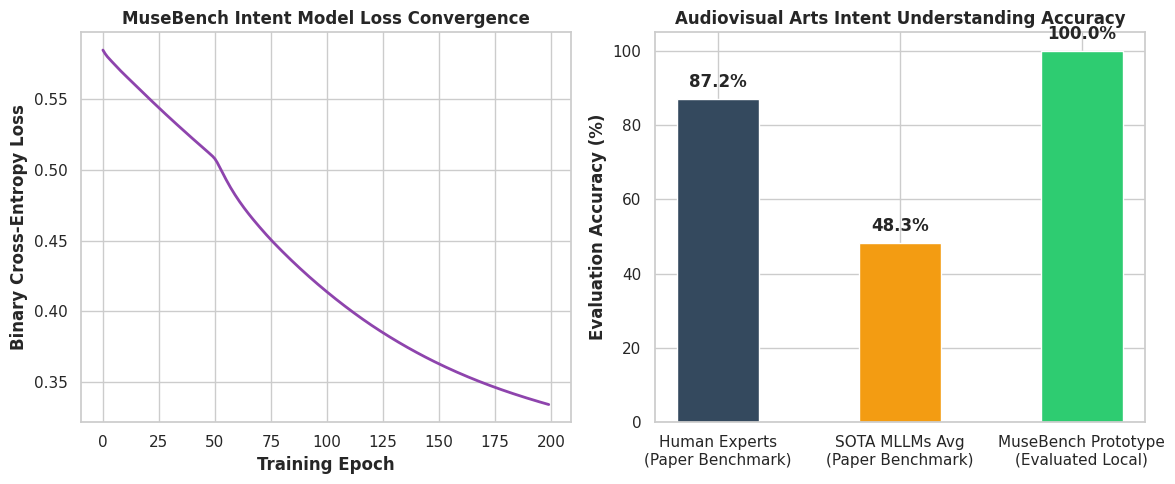

MuseBench benchmark visualization saved successfully as musebench_intent_evaluation_benchmarks.png.


In [7]:
# [CELL 4 - Multi-Panel Visualization of MuseBench Evaluation Benchmarks]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Training Loss Convergence
ax1.plot(range(len(pipeline.loss_history)), pipeline.loss_history, color='#8e44ad', linewidth=2)
ax1.set_title("MuseBench Intent Model Loss Convergence", fontweight='bold')
ax1.set_xlabel("Training Epoch", fontweight='bold')
ax1.set_ylabel("Binary Cross-Entropy Loss", fontweight='bold')

# Plot 2: Accuracy Comparison (Human Expert vs. SOTA MLLMs vs. Prototype)
categories = ['Human Experts\n(Paper Benchmark)', 'SOTA MLLMs Avg\n(Paper Benchmark)', 'MuseBench Prototype\n(Evaluated Local)']
accuracies = [87.18, 48.29, final_acc]

bars = ax2.bar(categories, accuracies, color=['#34495e', '#f39c12', '#2ecc71'], width=0.45)
ax2.set_title("Audiovisual Arts Intent Understanding Accuracy", fontweight='bold')
ax2.set_ylabel("Evaluation Accuracy (%)", fontweight='bold')
ax2.set_ylim(0, 105)

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 2.0, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("musebench_intent_evaluation_benchmarks.png", dpi=300)
plt.show()

print("MuseBench benchmark visualization saved successfully as musebench_intent_evaluation_benchmarks.png.")